# Proyecto Final: Tráfico aéreo y clima con APIs en la nube y cómputo paralelo

**Pregunta central:** ¿hay relación entre el clima de un aeropuerto y los retrasos de sus vuelos?

## Las 2 APIs que se usan
| API | Qué aporta | Por qué se eligió |
|---|---|---|
| **AirLabs** (`/schedules`) | Vuelos que salen de cada aeropuerto: horario, estado (programado, cancelado, aterrizado...) y minutos de retraso | Da los retrasos, las cancelaciones y los horarios |
| **OpenWeather** (clima actual) | Temperatura, humedad, presión, visibilidad, viento y lluvia en las coordenadas del aeropuerto | Da el clima para relacionarlo con los retrasos |

Con solo estas dos se responden las 5 preguntas de análisis del proyecto.

## Qué tecnología hace cada cosa
| Tecnología | Dónde se usa | Para qué |
|---|---|---|
| **Asyncio** (+ aiohttp) | Sección 4 | Consultar las dos APIs de **todos los aeropuertos al mismo tiempo** (lectura concurrente) |
| **Pandas** | Secciones 5, 7 y 9 | Limpiar los datos, unir vuelos con clima y responder preguntas |
| **MPI4Py** | Sección 6 | **Repartir entre procesos** el cálculo de estadísticas por aeropuerto |
| **CuPy (CUDA)** | Sección 8 | Calcular en la **GPU** la matriz de correlaciones y detectar valores atípicos |
| **Matplotlib** | Sección 10 | Visualizar los resultados |

## Flujo completo
```
APIs (AirLabs + OpenWeather)
        |  asyncio: peticiones concurrentes
        v
   Pandas: limpieza  --->  vuelos.csv
                                |
                                |  MPI4Py: cada proceso calcula las estadísticas de SUS aeropuertos
                                v
                     stats_aeropuertos.csv  --->  Pandas: unir con el clima
                                                        |
                                                        |  CuPy (GPU): correlaciones y atípicos
                                                        v
                                         respuestas + gráficas (Matplotlib)
```



## 1. Instalación de librerías
- **`libopenmpi-dev` y `openmpi-bin`:** el programa MPI real (la "máquina" que lanza y comunica procesos). `mpi4py` es solo el puente para usarlo desde Python.
- **`mpi4py`:** MPI desde Python.
- **`aiohttp`:** cliente HTTP **asíncrono**. La librería `requests` es síncrona y bloquearía cada petición; `aiohttp` permite lanzar muchas a la vez.
- Pandas, NumPy y Matplotlib ya vienen en Colab. CuPy normalmente también (con el entorno de GPU).

In [ ]:
!apt-get install -y -qq libopenmpi-dev openmpi-bin > /dev/null
!pip install -q mpi4py aiohttp



## 2. Importaciones y revisión de la GPU
En la GPU se usa un truco sencillo: se importa **CuPy** como `xp`. CuPy tiene casi la misma interfaz que NumPy, solo que ejecuta en la GPU. Si no hubiera GPU, `xp` pasa a ser NumPy y el resto del código funciona igual (en CPU).

In [ ]:
import asyncio       # herramientas de programación asíncrona (corrutinas, gather, Semaphore)
import time          # para medir cuánto tarda la descarga
import getpass       # para pedir las llaves por teclado si no están en los secretos
import aiohttp       # cliente HTTP asíncrono
import numpy as np   # arreglos numéricos en CPU
import pandas as pd  # tablas (DataFrame)
import matplotlib.pyplot as plt   # gráficas

try:
    import cupy as cp
    cp.cuda.runtime.getDeviceCount()   # si no hay GPU, esta línea lanza un error
    xp = cp                            
    GPU = True
except Exception:
    xp = np                            
    GPU = False

print("Cálculos numéricos en:", "GPU (CuPy / CUDA)" )

def a_cpu(x):
    """Pasa un arreglo de la memoria de la GPU a la memoria normal (NumPy).
    Pandas y Matplotlib solo entienden arreglos en CPU."""
    return cp.asnumpy(x) if GPU else x

Cálculos numéricos en: GPU (CuPy / CUDA)


## 3. Llaves de las APIs y configuración


In [ ]:
AIRLABS_KEY = ("d654d5e5-3507-49ac-90a6-323d9604556e")
OPENWEATHER_KEY = ("8e5da516a8128158113061528caa6ce2")


URL_AIRLABS = "https://airlabs.co/api/v9/schedules"                    # vuelos que salen de un aeropuerto
URL_CLIMA = "https://api.openweathermap.org/data/2.5/weather"          # clima actual en unas coordenadas


RETRASO_MIN = 15            # un vuelo cuenta como "retrasado" si sale con 15 min o más de retraso 
VISIBILIDAD_BAJA = 5000     # visibilidad menor a 5000 metros = "baja visibilidad"
MAX_SIMULTANEAS = 5         # máximo de peticiones HTTP al mismo tiempo 

AEROPUERTOS = {
    "CUU": ("Chihuahua",      28.7029, -105.9647),
    "MEX": ("Ciudad de México", 19.4363, -99.0721),
    "GDL": ("Guadalajara",    20.5218, -103.3112),
    "MTY": ("Monterrey",      25.7785, -100.1069),
    "CUN": ("Cancún",         21.0365,  -86.8771),
    "TIJ": ("Tijuana",        32.5411, -116.9700),
    "JFK": ("Nueva York JFK", 40.6413,  -73.7781),
    "LAX": ("Los Ángeles",    33.9416, -118.4085),
    "ATL": ("Atlanta",        33.6407,  -84.4277),
    "ORD": ("Chicago O'Hare", 41.9742,  -87.9073),
    "DFW": ("Dallas-Fort Worth", 32.8998, -97.0381),
    "MIA": ("Miami",          25.7959,  -80.2870),
    "LHR": ("Londres Heathrow", 51.4700,  -0.4543),
    "MAD": ("Madrid",         40.4983,   -3.5676),
    "CDG": ("París CDG",      49.0097,    2.5479),
}
print(len(AEROPUERTOS), "aeropuertos configurados")

## 4. Asyncio: leer las dos APIs de todos los aeropuertos a la vez

### La idea
Una petición HTTP pasa **casi todo su tiempo esperando** la respuesta del servidor. En código normal (síncrono) el programa se queda detenido en cada espera: 15 aeropuertos x 2 APIs = 30 esperas en fila.

Con **asyncio** el programa, mientras espera una respuesta, aprovecha para lanzar otras peticiones. Las 30 esperas se **traslapan** y el tiempo total se acerca al de la más lenta, no a la suma.

### Piezas
- **Corrutina (`async def`):** función que puede pausarse en un `await`.
- **`await`:** "pausa aquí hasta que esto termine, y mientras tanto el programa avanza otras corrutinas".
- **`asyncio.gather(...)`:** lanza varias corrutinas a la vez y espera a que todas terminen. Devuelve los resultados **en el mismo orden**.
- **`asyncio.Semaphore(n)`:** deja pasar a lo mucho `n` corrutinas a la vez por una sección. Evita mandar 30 peticiones de golpe y que la API nos bloquee (límite de peticiones).
- **Reintentos:** si una petición se agota (*timeout*) o llega incompleta, se reintenta hasta 3 veces con una pausa creciente. Si aun así falla, devuelve un diccionario con el error en lugar de lanzar una excepción, así **no se pierde** la otra API del mismo aeropuerto.
- **`aiohttp.ClientSession`:** una "sesión" que reutiliza conexiones entre peticiones.
- En un notebook ya hay un bucle de eventos corriendo, por eso se usa `await` **directamente** en la celda (no `asyncio.run`).

In [ ]:
async def pedir_json(sesion, url, params, semaforo, intentos=3):
    """Hace UNA petición GET (con hasta 3 intentos) y devuelve el JSON convertido a diccionario de Python.
    Si no hay respuesta tras los intentos, devuelve {"error": ..., "message": ...} en vez de lanzar una excepción."""
    for intento in range(1, intentos + 1):
        try:
            async with semaforo:                                      # pedir permiso al semáforo: máx. 5 peticiones dentro a la vez
                async with sesion.get(url, params=params) as respuesta:   # envía la petición (los params se agregan a la URL)
                    # await: aquí el programa se PAUSA esperando la respuesta, y otras peticiones avanzan
                    # content_type=None: acepta el JSON aunque el servidor no declare bien el tipo de contenido
                    return await respuesta.json(content_type=None)
        except (asyncio.TimeoutError, aiohttp.ClientError, ValueError) as error:
            if intento == intentos:
                # No se imprime el texto del error original: puede incluir la URL con la llave de la API
                mensaje = f"sin respuesta tras {intentos} intentos ({type(error).__name__})"
                return {"error": mensaje, "message": mensaje}
            await asyncio.sleep(2 * intento)                          # espera 2 s, luego 4 s, antes de reintentar (fuera del semáforo)


async def consultar_aeropuerto(sesion, semaforo, iata, lat, lon):
    """Para UN aeropuerto, pide sus vuelos (AirLabs) y su clima (OpenWeather) al mismo tiempo."""
    # Estas dos líneas SOLO preparan las corrutinas; todavía no se ejecutan
    tarea_vuelos = pedir_json(sesion, URL_AIRLABS,
                              {"api_key": AIRLABS_KEY, "dep_iata": iata}, semaforo)
    tarea_clima = pedir_json(sesion, URL_CLIMA,
                             {"lat": lat, "lon": lon, "appid": OPENWEATHER_KEY, "units": "metric"}, semaforo)
    # gather las lanza juntas y espera a las dos
    vuelos, clima = await asyncio.gather(tarea_vuelos, tarea_clima)
    return iata, vuelos, clima


async def descargar_todo():
    """Lanza la consulta de TODOS los aeropuertos a la vez."""
    semaforo = asyncio.Semaphore(MAX_SIMULTANEAS)           # se crea aquí, dentro del bucle de eventos
    espera_maxima = aiohttp.ClientTimeout(total=30)         # si UN intento tarda más de 30 s, se cancela (y se reintenta)
    async with aiohttp.ClientSession(timeout=espera_maxima) as sesion:
        tareas = [consultar_aeropuerto(sesion, semaforo, iata, lat, lon)
                  for iata, (_, lat, lon) in AEROPUERTOS.items()]
        # return_exceptions=True: si una consulta falla, NO cancela las demás; el error vuelve como resultado
        return await asyncio.gather(*tareas, return_exceptions=True)


# --- Ejecutar la descarga y medir el tiempo ---
t0 = time.perf_counter()
resultados = await descargar_todo()          # await directo (los notebooks lo permiten)
print(f"{len(resultados)} aeropuertos consultados (2 APIs cada uno) en {time.perf_counter() - t0:.2f} s")

## 5. Pandas: extraer, limpiar y guardar los datos

Cada respuesta es un JSON (diccionarios y listas). Aquí:
1. Se **extraen solo los campos necesarios** y se arman dos tablas (DataFrames): vuelos y clima.
2. Se **limpian**: los retrasos vienen vacíos cuando no hay retraso (se convierten a 0), se crean las columnas `retrasado`, `cancelado` y `hora`, y se quitan duplicados.
3. Los vuelos se guardan en **`vuelos.csv`**, porque el siguiente paso (MPI) corre como un **programa aparte** que lee ese archivo.

Si una API devuelve un error (por ejemplo, llave inválida o límite de peticiones), se imprime el mensaje para que sepas qué pasó.

In [ ]:
filas_vuelos = []   # aquí iremos juntando un diccionario por vuelo
filas_clima = []    # y un diccionario por aeropuerto con su clima

for r in resultados:
    # Si la consulta lanzó una excepción (red, tiempo agotado...), la reportamos y seguimos con las demás
    if isinstance(r, Exception):
        print("Falló una consulta:", repr(r))
        continue

    iata, vuelos_json, clima_json = r      # desempaquetamos la tupla que devolvió consultar_aeropuerto

    # ---------- AirLabs ----------
    # Si todo salió bien, la respuesta trae la lista de vuelos en la clave "response"
    if isinstance(vuelos_json, dict) and "response" in vuelos_json:
        for v in vuelos_json["response"]:
            # .get(campo) devuelve None si el campo no existe (en vez de dar error)
            filas_vuelos.append({
                "dep_iata": iata,                         # aeropuerto de salida
                "arr_iata": v.get("arr_iata"),            # aeropuerto de llegada
                "airline_iata": v.get("airline_iata"),    # aerolínea
                "flight_iata": v.get("flight_iata"),      # número de vuelo
                "status": v.get("status"),                # scheduled / active / landed / cancelled
                "dep_time": v.get("dep_time"),            # hora programada de salida (hora local)
                "dep_delayed": v.get("dep_delayed"),      # minutos de retraso en la salida (si hay)
            })
    else:
        print(f"AirLabs ({iata}):", vuelos_json.get("error", vuelos_json) if isinstance(vuelos_json, dict) else vuelos_json)

    # ---------- OpenWeather ----------
    # Si todo salió bien, la respuesta trae la clave "main" (temperatura, humedad, presión)
    if isinstance(clima_json, dict) and "main" in clima_json:
        filas_clima.append({
            "dep_iata": iata,
            "temp": clima_json["main"]["temp"],                     # temperatura en °C
            "humedad": clima_json["main"]["humidity"],              # humedad en %
            "presion": clima_json["main"]["pressure"],              # presión en hPa
            "visibilidad": clima_json.get("visibility", 10000),     # metros (10000 = máximo que reporta la API)
            "viento": clima_json.get("wind", {}).get("speed", 0.0), # velocidad del viento en m/s
            "lluvia_mm": clima_json.get("rain", {}).get("1h", 0.0), # lluvia de la última hora en mm (no viene si no llueve)
            "condicion": clima_json["weather"][0]["main"],          # Clear, Clouds, Rain...
        })
    else:
        print(f"OpenWeather ({iata}):", clima_json.get("message", clima_json) if isinstance(clima_json, dict) else clima_json)

# --- Convertir las listas de diccionarios en tablas de Pandas ---
vuelos = pd.DataFrame(filas_vuelos)
clima = pd.DataFrame(filas_clima)

if vuelos.empty or clima.empty:
    raise RuntimeError("No llegaron datos. Revisa los mensajes de arriba (llaves, límite de peticiones, etc.).")

# --- Limpieza ---
# 1) dep_delayed -> número; lo que no sea número o venga vacío se vuelve 0 (sin retraso)
vuelos["dep_delayed"] = pd.to_numeric(vuelos["dep_delayed"], errors="coerce").fillna(0)
# 2) retrasado: True si el retraso llega al mínimo definido (15 min)
vuelos["retrasado"] = vuelos["dep_delayed"] >= RETRASO_MIN
# 3) cancelado: True si el estado es "cancelled"
vuelos["cancelado"] = vuelos["status"] == "cancelled"
# 4) hora: la hora del día (0-23) de la salida programada; si el texto no se puede leer queda vacía
vuelos["hora"] = pd.to_datetime(vuelos["dep_time"], errors="coerce").dt.hour
# 5) quitar vuelos repetidos
vuelos = vuelos.drop_duplicates(subset=["flight_iata", "dep_iata", "dep_time"])

# Guardar para el paso de MPI (que es un programa independiente)
vuelos.to_csv("vuelos.csv", index=False)

print("Vuelos:", len(vuelos), "| Aeropuertos con vuelos:", vuelos["dep_iata"].nunique(),
      "| Aeropuertos con clima:", len(clima))
print("Vuelos retrasados:", int(vuelos["retrasado"].sum()), "| cancelados:", int(vuelos["cancelado"].sum()))
vuelos.head()

Falló una consulta: TimeoutError()
Falló una consulta: ClientPayloadError("Response payload is not completed: <TransferEncodingError: 400, message='Not enough data to satisfy transfer length header.'>")
Falló una consulta: TimeoutError()
Falló una consulta: TimeoutError()
Vuelos: 932 | Aeropuertos con vuelos: 11 | Aeropuertos con clima: 11
Vuelos retrasados: 179 | cancelados: 1


,dep_iata,arr_iata,airline_iata,flight_iata,status,dep_time,dep_delayed,retrasado,cancelado,hora
0,CUU,MTY,VB,VB4319,landed,2026-11-18 21:51,27.0,True,False,21
1,CUU,GDL,Y4,Y41223,landed,2026-11-18 21:58,0.0,False,False,21
2,CUU,GDL,CM,CM3166,landed,2026-11-18 21:58,0.0,False,False,21
3,CUU,MTY,AV,AV6805,scheduled,2026-11-19 06:00,0.0,False,False,6
4,CUU,MTY,VB,VB4311,scheduled,2026-11-19 06:00,0.0,False,False,6


## 6. MPI4Py: repartir el cálculo por aeropuerto entre procesos

### La idea
MPI lanza **varias copias del mismo programa (procesos)**. Cada copia sabe quién es mediante su **`rank`** (0, 1, ...) y cuántas hay (**`size`**). Los procesos **no comparten memoria**; solo se pasan mensajes. Es el modelo **SPMD**: mismo programa, datos distintos.

### Qué se reparte aquí
Las estadísticas **por aeropuerto** (número de vuelos, retraso promedio, % retrasados, cancelados) son independientes entre aeropuertos, así que se pueden repartir:
- Cada proceso toma **sus** aeropuertos con `aeropuertos[rank::size]` (reparto "por turnos", como repartir cartas).
- Calcula las estadísticas de los suyos con Pandas.
- **`comm.gather`** junta los resultados en el proceso 0, que guarda `stats_aeropuertos.csv`.

### Por qué un archivo `.py` aparte
MPI necesita lanzar **procesos nuevos**, y un notebook es un solo proceso. Por eso el código MPI se escribe a un archivo con `%%writefile` y se ejecuta con **`mpiexec`**. Los datos viajan por archivos (`vuelos.csv` de entrada y `stats_aeropuertos.csv` de salida).

> Colab tiene pocos núcleos (normalmente 2), así que usamos 2 procesos. Con tan pocos datos MPI **no hace más rápido** el cálculo (lanzar procesos cuesta más que lo que se ahorra); se usa para aplicar la distribución del procesamiento que pide el proyecto.

In [ ]:
%%writefile mpi_estadisticas.py
# ===== Este archivo lo ejecuta CADA proceso MPI (todos corren este mismo código) =====
from mpi4py import MPI
import pandas as pd

comm = MPI.COMM_WORLD          # el "grupo" con todos los procesos
rank = comm.Get_rank()         # MI número de proceso (0, 1, ...)
size = comm.Get_size()         # cuántos procesos somos en total

# Todos los procesos leen el mismo archivo (cada uno en su propia memoria)
df = pd.read_csv("vuelos.csv")

# Lista ordenada de aeropuertos; todos obtienen la MISMA lista
aeropuertos = sorted(df["dep_iata"].unique())

# Reparto por turnos: el proceso 0 toma los aeropuertos 0, 2, 4...; el 1 toma el 1, 3, 5...
mios = aeropuertos[rank::size]

# Me quedo solo con los vuelos de MIS aeropuertos
parte = df[df["dep_iata"].isin(mios)]

# Estadísticas por aeropuerto (groupby agrupa, agg calcula varias cosas a la vez)
stats = parte.groupby("dep_iata").agg(
    vuelos=("status", "size"),                  # cuántos vuelos hay
    retraso_prom=("dep_delayed", "mean"),       # retraso promedio en minutos
    pct_retrasados=("retrasado", "mean"),       # fracción de vuelos retrasados (0 a 1)
    cancelados=("cancelado", "sum"),            # cuántos cancelados
).reset_index()
stats["pct_retrasados"] = stats["pct_retrasados"] * 100   # pasar de fracción a porcentaje

print(f"[proceso {rank} de {size}] calculó {len(mios)} aeropuertos: {mios}")

# gather: todos envían su tabla al proceso 0, que recibe una LISTA con una tabla por proceso
todos = comm.gather(stats, root=0)

# Solo el proceso 0 junta las tablas y guarda el resultado
if rank == 0:
    pd.concat(todos).sort_values("dep_iata").to_csv("stats_aeropuertos.csv", index=False)
    print("[proceso 0] guardó stats_aeropuertos.csv")

Writing mpi_estadisticas.py


In [ ]:
# Ejecuta el archivo con 2 procesos MPI.
#   -n 2                 -> 2 procesos
#   --allow-run-as-root  -> Colab corre como "root" y MPI lo prohíbe por defecto
#   --oversubscribe      -> permite más procesos que núcleos disponibles
!mpiexec -n 2 --allow-run-as-root --oversubscribe python mpi_estadisticas.py

[proceso 0 de 2] calculó 6 aeropuertos: ['ATL', 'CUU', 'GDL', 'LAX', 'MTY', 'TIJ']
[proceso 1 de 2] calculó 5 aeropuertos: ['CUN', 'DFW', 'JFK', 'MIA', 'ORD']
[proceso 0] guardó stats_aeropuertos.csv


## 7. Pandas: unir las estadísticas con el clima
Se juntan las dos tablas por el código del aeropuerto (`dep_iata`). Es el equivalente a un `JOIN` de SQL. Queda **una fila por aeropuerto** con sus estadísticas de vuelos y su clima.

In [ ]:
# Leemos el resultado que dejó MPI
stats = pd.read_csv("stats_aeropuertos.csv")

# merge: une dos tablas usando la columna en común (por defecto solo deja los aeropuertos que están en AMBAS)
datos = stats.merge(clima, on="dep_iata")

# Nombre legible del aeropuerto (buscamos el código en nuestro diccionario)
datos["nombre"] = datos["dep_iata"].map(lambda iata: AEROPUERTOS[iata][0])

# Cantidad de vuelos retrasados = porcentaje * vuelos / 100
datos["n_retrasados"] = (datos["pct_retrasados"] / 100 * datos["vuelos"]).round()

datos[["dep_iata", "nombre", "vuelos", "retraso_prom", "pct_retrasados", "cancelados",
       "temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm", "condicion"]]

,dep_iata,nombre,vuelos,retraso_prom,pct_retrasados,cancelados,temp,humedad,presion,visibilidad,viento,lluvia_mm,condicion
0,ATL,Atlanta,100,2.200000,9.000000,0,12.50,49,1030,10000,6.17,0.0,Clouds
1,CUN,Cancún,59,4.610169,5.084746,0,24.00,94,1015,10000,0.00,0.0,Clouds
2,CUU,Chihuahua,23,1.173913,4.347826,0,12.84,71,1020,10000,0.16,0.0,Clouds
3,DFW,Dallas-Fort Worth,100,25.120000,23.000000,0,13.44,84,1024,10000,1.79,0.0,Clear
4,GDL,Guadalajara,100,2.870000,4.000000,0,16.00,82,1019,9656,0.00,0.0,Clouds
5,JFK,Nueva York JFK,100,13.620000,15.000000,1,9.66,62,1031,10000,3.58,0.0,Clear
6,LAX,Los Ángeles,100,31.400000,35.000000,0,17.02,73,1017,10000,2.06,0.0,Clear
7,MIA,Miami,100,118.140000,48.000000,0,22.59,91,1016,10000,3.09,0.0,Clouds
8,MTY,Monterrey,100,21.370000,8.000000,0,17.00,82,1023,10000,1.54,0.0,Clouds
9,ORD,Chicago O'Hare,100,33.960000,29.000000,0,11.25,57,1026,10000,5.14,0.0,Clouds


## 8. CuPy (CUDA): correlaciones y valores atípicos en la GPU

### Qué es CuPy
Biblioteca con la interfaz de NumPy que ejecuta los cálculos en la **GPU NVIDIA** mediante **CUDA**. El flujo es: copiar los datos de la memoria normal a la memoria de la GPU (`xp.asarray`), calcular allí, y traer el resultado de vuelta (`a_cpu`).

### Qué se calcula
1. **Matriz de correlación** (`corrcoef`): qué tan relacionadas están todas las variables entre sí (retrasos, tráfico y clima). Va de -1 a 1: cerca de 1 = suben juntas, cerca de -1 = una sube y la otra baja, cerca de 0 = no hay relación lineal.
2. **Valores atípicos** con la **puntuación z**: `z = (valor - promedio) / desviación estándar`. Si `|z| > 3`, el retraso está a más de 3 desviaciones del promedio y se marca como atípico.

> Con tan pocos datos la GPU **no es más rápida** que la CPU (copiar a la GPU cuesta más que calcular). Se usa para aplicar la aceleración con CUDA que pide el proyecto; el beneficio real aparece con millones de datos.

In [ ]:
# ---------- 1) Matriz de correlación (aeropuertos x variables) ----------
variables = ["retraso_prom", "pct_retrasados", "vuelos",
             "temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm"]

# Si una variable es constante (por ejemplo, visibilidad = 10000 en todos, o 0 mm de lluvia en todos),
# su correlación no se puede calcular (división entre 0). La quitamos.
variables = [v for v in variables if datos[v].std() > 0]

# Tabla -> arreglo NumPy de decimales -> arreglo en la GPU (xp.asarray hace la copia)
matriz = xp.asarray(datos[variables].to_numpy(dtype="float64"))

# corrcoef calcula la correlación entre columnas (rowvar=False: cada COLUMNA es una variable)
# El cálculo ocurre en la GPU; a_cpu() trae el resultado de vuelta
corr = a_cpu(xp.corrcoef(matriz, rowvar=False))
tabla_corr = pd.DataFrame(corr, index=variables, columns=variables)   # con nombres para leerla mejor

# ---------- 2) Valores atípicos en los retrasos (puntuación z) ----------
retrasos = xp.asarray(vuelos["dep_delayed"].to_numpy(dtype="float64"))   # un retraso por vuelo, a la GPU
desviacion = float(retrasos.std())                                       # float() trae el número a la CPU

if desviacion > 0:
    z = (retrasos - retrasos.mean()) / desviacion        # puntuación z de cada vuelo (todo en la GPU)
    vuelos["atipico"] = a_cpu(xp.abs(z) > 3)             # True si está a más de 3 desviaciones
else:
    vuelos["atipico"] = False                            # nadie tuvo retraso: no hay atípicos

print("Matriz de correlación calculada con", "CuPy (GPU)" if GPU else "NumPy (CPU)")
print("Vuelos con retraso atípico (|z| > 3):", int(vuelos["atipico"].sum()), "de", len(vuelos))
tabla_corr.round(2)

Matriz de correlación calculada con CuPy (GPU)
Vuelos con retraso atípico (|z| > 3): 26 de 932


,retraso_prom,pct_retrasados,vuelos,temp,humedad,presion,visibilidad,viento
retraso_prom,1.00,0.88,0.38,0.44,0.31,-0.27,0.20,0.21
pct_retrasados,0.88,1.00,0.48,0.22,0.08,-0.15,0.30,0.36
vuelos,0.38,0.48,1.00,-0.05,-0.18,0.39,-0.18,0.46
temp,0.44,0.22,-0.05,1.00,0.79,-0.79,-0.04,-0.45
humedad,0.31,0.08,-0.18,0.79,1.00,-0.80,-0.17,-0.75
presion,-0.27,-0.15,0.39,-0.79,-0.80,1.00,0.16,0.67
visibilidad,0.20,0.30,-0.18,-0.04,-0.17,0.16,1.00,0.39
viento,0.21,0.36,0.46,-0.45,-0.75,0.67,0.39,1.00


## 9. Respuestas a las preguntas de análisis
Todas salen de **tus datos de este momento**. Recuerda que es una **foto instantánea** (un aeropuerto = un punto), así que con ~15 aeropuertos las correlaciones son una **pista**, no una prueba.

In [ ]:
clima_vars = [v for v in ["temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm"] if v in variables]
objetivos = [v for v in ["retraso_prom", "pct_retrasados"] if v in variables]

# ---------- P1: ¿Hay relación entre clima y retrasos? ----------
print("P1. ¿Hay relación entre clima y retrasos?")
if objetivos and clima_vars:
    print("Correlación de cada variable del clima con los retrasos (de -1 a 1):")
    print(tabla_corr.loc[clima_vars, objetivos].round(2))
    mejor = tabla_corr.loc[clima_vars, objetivos[-1]].abs().idxmax()      # la variable más relacionada
    print(f"-> La variable con mayor relación (en valor absoluto) con '{objetivos[-1]}' es '{mejor}' "
          f"({tabla_corr.loc[mejor, objetivos[-1]]:.2f}).")
else:
    print("No hay suficientes datos con variación (por ejemplo, no hubo retrasos) para calcular correlaciones.")

# ---------- P2: ¿Aumentan los retrasos con lluvia o baja visibilidad? ----------
print("\nP2. ¿Aumentan los retrasos con lluvia o baja visibilidad?")
# mal_clima = True si hay lluvia O la visibilidad es baja
datos["mal_clima"] = (datos["lluvia_mm"] > 0) | (datos["visibilidad"] < VISIBILIDAD_BAJA)
grupos = datos.groupby("mal_clima")["pct_retrasados"].agg(["mean", "count"])   # promedio de % retrasados y nº de aeropuertos
grupos.index = grupos.index.map({True: "Con lluvia / baja visibilidad", False: "Clima normal"})
grupos.columns = ["% retrasados (promedio)", "aeropuertos"]
print(grupos.round(1))
if len(grupos) < 2:
    print("-> Todos los aeropuertos están en el mismo grupo ahora mismo; no se puede comparar lluvia / baja visibilidad. Vuelve a correrlo en otro momento.")
    # Comparación alternativa con lo que sí varía: la condición del cielo (Clear, Clouds, ...)
    alt = datos.groupby("condicion")[["pct_retrasados", "retraso_prom"]].mean()
    alt["aeropuertos"] = datos.groupby("condicion").size()
    alt.columns = ["% retrasados (promedio)", "retraso prom. (min)", "aeropuertos"]
    print("\nComparación alternativa por condición del cielo:")
    print(alt.round(1))

# ---------- P3: ¿Qué aeropuertos tienen más retrasos? ----------
print("\nP3. Aeropuertos con más vuelos retrasados:")
ranking = datos.sort_values(["n_retrasados", "pct_retrasados"], ascending=False)
print(ranking[["dep_iata", "nombre", "vuelos", "n_retrasados", "pct_retrasados", "retraso_prom"]].head(5).round(1).to_string(index=False))

# ---------- P4: ¿Cómo cambia la actividad aérea durante el día? ----------
print("\nP4. Salidas programadas por hora del día (todos los aeropuertos):")
por_hora = vuelos.dropna(subset=["hora"]).groupby("hora").size()    # cuántos vuelos salen en cada hora
if len(por_hora):
    print(f"-> Hora con más salidas: {int(por_hora.idxmax())}:00 ({int(por_hora.max())} vuelos) | "
          f"hora con menos: {int(por_hora.idxmin())}:00 ({int(por_hora.min())} vuelos)")

# ---------- P5: ¿Qué condiciones ambientales coinciden con más tráfico aéreo? ----------
print("\nP5. Correlación de las condiciones ambientales con la cantidad de vuelos:")
if "vuelos" in variables and clima_vars:
    print(tabla_corr.loc[clima_vars, "vuelos"].round(2).to_string())
else:
    print("No hay variación suficiente para calcular correlaciones.")

### Revisión de robustez (antes de concluir)
Con tan pocos aeropuertos, **un solo aeropuerto con retrasos muy grandes puede inventar una correlación**. Esta celda revisa tres cosas:
1. En qué aeropuertos están los retrasos atípicos.
2. Cómo cambian las correlaciones **sin** el aeropuerto de mayor retraso promedio. Si cambian mucho, esa relación no es confiable.
3. Cuántos aeropuertos llegaron al **tope de vuelos** que devuelve la consulta de AirLabs (si muchos tienen el mismo número, la variable `vuelos` es solo el tope de la API y no el tráfico real).

In [ ]:
# 1) Retrasos atípicos por aeropuerto
print("Vuelos con retraso atípico (|z| > 3) por aeropuerto:")
print(vuelos[vuelos["atipico"]].groupby("dep_iata").size().sort_values(ascending=False).to_string())

# 2) Correlaciones sin el aeropuerto de mayor retraso promedio
peor = datos.loc[datos["retraso_prom"].idxmax(), "dep_iata"]
sin = datos[datos["dep_iata"] != peor]
print(f"\nCorrelación con los retrasos SIN {peor} ({len(sin)} aeropuertos):")
print(sin[clima_vars + objetivos].corr().loc[clima_vars, objetivos].round(2))

# 3) ¿Cuántos aeropuertos llegaron al tope de vuelos de la consulta?
tope = datos["vuelos"].max()
print(f"\nAeropuertos con {tope} vuelos (probable tope de la API): {(datos['vuelos'] == tope).sum()} de {len(datos)}")

## 10. Visualización con Matplotlib

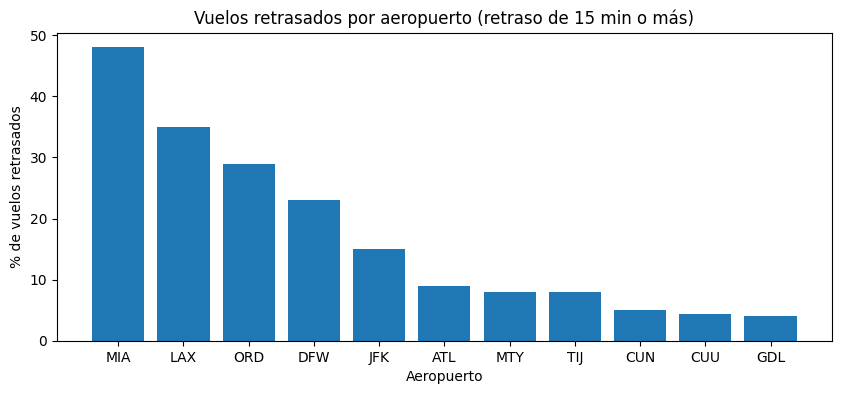

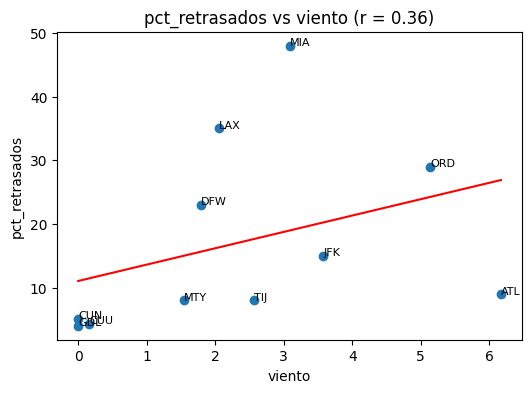

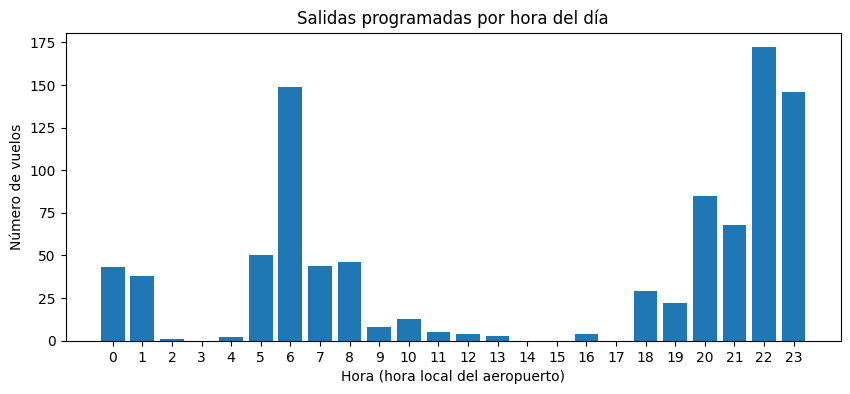

In [ ]:
# ---------- Gráfica 1: % de vuelos retrasados por aeropuerto ----------
orden = datos.sort_values("pct_retrasados", ascending=False)          # ordenamos de mayor a menor
plt.figure(figsize=(10, 4))
plt.bar(orden["dep_iata"], orden["pct_retrasados"])                   # una barra por aeropuerto
plt.title("Vuelos retrasados por aeropuerto (retraso de 15 min o más)")
plt.xlabel("Aeropuerto"); plt.ylabel("% de vuelos retrasados")
plt.show()

# ---------- Gráfica 2: variable del clima más relacionada con los retrasos ----------
if objetivos and clima_vars:
    objetivo = objetivos[-1]                                          # pct_retrasados (o retraso_prom si no hay otro)
    var = tabla_corr.loc[clima_vars, objetivo].abs().idxmax()         # la variable con mayor |correlación|
    plt.figure(figsize=(6, 4))
    plt.scatter(datos[var], datos[objetivo])                          # un punto por aeropuerto
    for _, f in datos.iterrows():                                     # etiqueta cada punto con su código
        plt.annotate(f["dep_iata"], (f[var], f[objetivo]), fontsize=8)
    if datos[var].nunique() > 1:                                      # línea de tendencia (ajuste lineal)
        m, b = np.polyfit(datos[var], datos[objetivo], 1)             # pendiente e intercepto
        xs = np.linspace(datos[var].min(), datos[var].max(), 50)
        plt.plot(xs, m * xs + b, color="red")
    plt.title(f"{objetivo} vs {var} (r = {tabla_corr.loc[var, objetivo]:.2f})")
    plt.xlabel(var); plt.ylabel(objetivo)
    plt.show()

# ---------- Gráfica 3: actividad aérea por hora del día ----------
if len(por_hora):
    plt.figure(figsize=(10, 4))
    plt.bar(por_hora.index, por_hora.values)
    plt.title("Salidas programadas por hora del día")
    plt.xlabel("Hora (hora local del aeropuerto)"); plt.ylabel("Número de vuelos")
    plt.xticks(range(0, 24))
    plt.show()

## 11. Guía para exponer

**En una frase:** se descargan en paralelo vuelos y clima de 15 aeropuertos, se limpian con Pandas, se calculan estadísticas por aeropuerto repartidas con MPI, se calculan correlaciones y atípicos en la GPU con CuPy, y se responden las preguntas con gráficas.

**Orden para explicarlo**
1. **Asyncio (sec. 4):** las peticiones HTTP son esperas de red; `gather` las traslapa y `Semaphore` limita cuántas van a la vez.
2. **Pandas (sec. 5 y 7):** del JSON a tablas; limpieza (retraso vacío = 0, columnas `retrasado`, `cancelado`, `hora`); `merge` para unir vuelos y clima.
3. **MPI4Py (sec. 6):** SPMD, `rank`/`size`, reparto `aeropuertos[rank::size]`, `gather` al proceso 0. Se corre con `mpiexec` porque necesita varios procesos.
4. **CuPy (sec. 8):** misma interfaz que NumPy pero en la GPU; datos a GPU → cálculo → resultado a CPU.
5. **Resultados (sec. 9 y 10):** respuestas a las 5 preguntas con tus datos.

**Preguntas que pueden hacerte**
- *¿Por qué asyncio y no threads?* Para tareas de espera de red, asyncio es más ligero: un solo hilo y miles de esperas simultáneas, sin los problemas de sincronización de los threads.
- *¿Para qué sirve el Semaphore?* Para limitar las peticiones simultáneas y no pasar el límite de las APIs.
- *¿Por qué MPI usa un archivo `.py` aparte?* Porque MPI lanza procesos nuevos; un notebook es un solo proceso.
- *¿MPI y la GPU aceleraron algo aquí?* No: son pocos datos y el costo de lanzar procesos o copiar a la GPU es mayor que el cálculo. Se usan para aplicar la técnica; el beneficio llega con muchos datos.
- *¿Por qué el resultado no es concluyente?* Son pocos aeropuertos, una sola foto del clima y retrasos que dependen de muchas otras causas (tráfico, tripulación, mantenimiento). Para concluir mejor habría que repetir la medición durante varios días.
- *¿Cómo se definió "retrasado"?* Salida con 15 minutos o más de retraso.
- *¿Y los atípicos?* Retrasos con puntuación z mayor a 3 en valor absoluto.

**Limitaciones que conviene mencionar:** el plan gratuito de las APIs limita las peticiones y los datos (AirLabs devuelve como máximo 100 vuelos por aeropuerto, así que la cantidad de vuelos de varios aeropuertos es solo ese tope); algunas consultas pueden fallar por *timeout* y el notebook las reintenta, pero si siguen fallando se pierde ese aeropuerto; los vuelos que aún no han salido tienen retraso 0 porque todavía no se conoce, lo que subestima el porcentaje de retrasados; el clima es el de *ahora* mientras los vuelos son los próximos de la lista de AirLabs; la correlación no implica causalidad.